# ✈️ Island Hopper in a notebook

This notebook shows how to use the `island_hopper` project to plan and visualize the flight path of a small airplane:

1. **Setup**: import the package and prepare the notebook
2. **Introduction**: explanation of project's purpose and functionality
3. **Cleaning and copying the airports database**: Filter and save valid airports
4. **Creating the graph**: Build graph with airports as nodes and flights as edges
5. **The network of airports, visualized**: Display entire network
6. **BFS: What is the minimum amount of stops needed to reach an airport?**: Find the route with the fewest flights
7. **BFS: What is the farthest airport that you can reach with at most 10 stops?**: Find the farthest reachable airport
8. **Dijkstra: What is the minimum amount of time needed to reach an airport?**: Find the fastest available route.

Every function used here comes from the `island_hopper/` folder.

**How to run it.** Install the requirements (`pip install -r requirements.txt`),
then start Jupyter from the project folder with `jupyter lab` and open
`notebooks/island_hopper_walkthrough.ipynb`. Run the cells from top to bottom
(*Run → Run All Cells*).

## 1. Setup

The notebook lives in the `notebooks/` folder, while the `island_hopper` package and the `data/` folder are one level up, in the project folder. Python only looks for packages in a few places, so we add the project folder to that list (`sys.path`) to make the `island_hopper` modules accessible. 

In [2]:
import os
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# The notebook is inside the notebooks/ folder, so the project folder is its parent.
NOTEBOOK_DIR = os.getcwd()
PROJECT_ROOT = os.path.dirname(NOTEBOOK_DIR)

# Let Python find the island_hopper package.
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

print("Island Hopper notebook environment is ready")
print("Project folder:", os.path.basename(PROJECT_ROOT))

Island Hopper notebook environment is ready
Project folder: Python Project Airports


In [3]:
# Importing the modules of the package needed.
from island_hopper.extractor import cleanAirports, extractValidAirports, edgesPopulator
from island_hopper.haversine import haversineFormula
from island_hopper.bfs import breadthFirstSearch, FurthestPointFunction
from island_hopper.dijkstra import MinimumTimeFunction
from island_hopper.visualization import VisualizeEntireGraph, VisualizeRouteInEntireGraph,VisualizeRoute

## 2. Introduction

Island Hopper is a Python project that allows you to model a network of airports and plan an optimal route so that a small plane can fly from one airport to another in the network, only by using databases of the airports.

The small airplane has certain criterias about its landing airports:
1. Can only land on large and medium airports
2. Has a predefined maximum range of kilometers / maximum fuel tank
3. Each flight takes 1 hour every 500 km
4. Every time it reaches an intermediary airport, it takes 1 hour for refuelling
5. Whenever the small plane lands in a difference country than the one it departed from, it needs some time for customs

The objectives of the project are:
1. Starting from Milan Malpensa (or any other airport), what is the minimum amount of stops needed to reach Sydney (or any other destination)?
2. What is the farthest airport that can be reached with at most 10 stops?
3. Starting from Milan Malpensa (or any other airport), what is the minimum amount of time needed to reach Sydney (or any other destination)?

The project utilizes the [OurAirports](https://ourairports.com/data/) dataset ([Github](https://github.com/davidmegginson/ourairports-data)), which describes airports all over the world. The datasets from that website which were considered relevant for solving the objectives are:
1. `airports.csv`
2. `countries.csv`
3. `regions.csv`

With all of these assumptions and objectives in mind, the Island Hopper project uses graph algorithms in order to achieve the objectives of the small airplane.

## 3. Cleaning and copying the airports database

Looking at the small airplane's first criteria (can only land on large and medium airports), this means that the airport records in `airports.csv` aren't all valid landing locations. Therefore, it is possible to create a CSV file that is a copy of `airports.csv`, that has been cleaned. This means that the small airplane will have only valid airports to land on in the new CSV file (`validAirports.csv`).

The `cleanAirports` function filters the original dataset to:
- include only medium or large airports
- exclude records which have missing values in the required attributes

In [4]:
# Cleaning and filtering
numberOfAirports = cleanAirports()
print(f"Number of valid airports: {numberOfAirports}")

Number of valid airports: 4450


## 4. Creating the graph 

Since this new CSV file, named `validAirports.csv`, only contains valid locations where the small airplane can land, it is possible to use only this CSV file to complete the objectives.
To complete the objectives, graph theory is needed to be used. Therefore, `validAirports.csv` must be turned into a weighted graph, in which the airports are the **nodes** and the **weighted edges** are the time it takes to get to the next airport.

Function `extractValidAirports` was used in order to take the attributes from the valid aiport CSV file and inserts them into a dictionary in a specific format. This way we have created the nodes of the graph, without the edges.

In [5]:
# Extracting only the airports as nodes.
airports = extractValidAirports()

print(f"Number of nodes: {len(airports)}")

Number of nodes: 4450


In [6]:
# Inspecting the dictionary format of some of the airports' records
# The "edges" key is a dictionary that will hold every single possible successor node that can be reached from the current node. It is an empty because it will get populated later.

# "4340" is the ID of the Milan Malpensa International Airport
print(airports["4340"])

# "4372" is the ID of the Rome–Fiumicino Leonardo da Vinci International Airport
print(airports["4372"])

# "3622" is the ID of the John F. Kennedy International Airport
print(airports["3622"])

{'name': 'Milan Malpensa International Airport', 'latitude': 45.6306, 'longitude': 8.72811, 'country': 'IT', 'continent': 'EU', 'edges': []}
{'name': 'Rome–Fiumicino Leonardo da Vinci International Airport', 'latitude': 41.804532, 'longitude': 12.251998, 'country': 'IT', 'continent': 'EU', 'edges': []}
{'name': 'John F. Kennedy International Airport', 'latitude': 40.639447, 'longitude': -73.779317, 'country': 'US', 'continent': 'NA', 'edges': []}


In order to create the edges between the nodes, the small airplane's second condition must be considered: has a predefined maximum range of kilometers / maximum fuel tank. If the small airplane has a `k` maximum range of kilometers / maximum fuel tank, then, starting from an origin airport, the small airplane can only travel `≤ k` kilometers to reach the next airport. Therefore, the first node (the origin airport) has a succesful edge to the successor node (the next airport) if, and only if, the distance between the 2 nodes is `≤ k` kilometers. In other words, the small airplane can fly between the two airports if the distance between them is smaller than the plane's maximum range of kilometers.

### How to find the distance between 2 airports from the CSV file?

Every airport in `validAirports.csv` has a `latitude_deg` and `longitude_deg` attribute which states the exact latitude and longitude coordinates of that specific airport. If the latitude and longitude coordinates of the 2 airports are known, then the **Haversine Formula** can be used. The formula calculates the distance between two points on Earth using their geographic coordinates. The function `haversineFormula` does this.

In [7]:
airport1 = [45.6306,8.72811] # Milan Malpensa International Airport
airport2 = [41.804532,12.251998] # Rome–Fiumicino Leonardo da Vinci International Airport

print(f"Distance between Milan Malpensa Airport and Rome-Fiumicino Airport is {round(haversineFormula(airport1[0],airport1[1],airport2[0],airport2[1]), 2)} km")

Distance between Milan Malpensa Airport and Rome-Fiumicino Airport is 510.96 km


With this function, it is possible to populate each airports' `edges` dictionary by calculating the distance between that origin airport and every other successor airport in the graph. However, only the successor nodes that have a distance between them and the origin node less or equal than `k` kilometers will be added to the `edges` dictionary. 

For each edge, to make it weighted, the time was calculated as well. This was done by considering the third (each flight takes 1 hour every 500 km) and fifth (whenever the small plane lands in a difference country than the one it departed from, it needs some time for customs) conditions of the small plane. For every `edges` dictionary a key `duration_hours` was added with the value being **(the distance between 2 airports/500)** (every 500 km is an hour) and another key `customs_hour` was added with the value being 1 or 0 depending if the origin airport's country is the same as the successor airport's country.

In [ ]:
# Maximum flight range in kilometres
maxRange = 500.00

output = edgesPopulator(airports, maxRange)

print(list(output.items())[:2])

[('6924', {'name': 'Ocean Reef Club Airport', 'latitude': 25.325399, 'longitude': -80.274803, 'country': 'US', 'continent': 'NA', 'edges': [{'destination': '19293', 'distance': np.float64(176.2031449068518), 'duration_hours': np.float64(0.3524062898137036), 'customs_hour': 0, 'totalTime_hours': np.float64(0.3524062898137036)}, {'destination': '19359', 'distance': np.float64(118.28734072128172), 'duration_hours': np.float64(0.23657468144256344), 'customs_hour': 0, 'totalTime_hours': np.float64(0.23657468144256344)}, {'destination': '3462', 'distance': np.float64(325.2287699487453), 'duration_hours': np.float64(0.6504575398974907), 'customs_hour': 0, 'totalTime_hours': np.float64(0.6504575398974907)}, {'destination': '3478', 'distance': np.float64(435.8481021240654), 'duration_hours': np.float64(0.8716962042481308), 'customs_hour': 0, 'totalTime_hours': np.float64(0.8716962042481308)}, {'destination': '3522', 'distance': np.float64(172.41615588818942), 'duration_hours': np.float64(0.3448

With all of this done, the graph of each airport from `validAirports.csv` was done, where each airport is the node and, the time it takes to get to another valid airport, being the weighted edge.
It is possible that the user chooses the maximum flight range of the small airplane. Based on this value, the `edgesPopulator` function calculates the distances between airports and creates the corresponding edges/flights between the nodes. 

Since the possible connections depend on the aircraft's maximum range, the graph must be rebuilt whenever the user changes this value. For example, a range of **500 km** produces a different network from a range of **750 km**. The higher the maximum range, the more airport connections and opportunities the small airplane will be able to take. Some airports may be unreachable with a smaller maximum flight range. Only by increasing this value, it allows the plane to reach airports that were previously unavailable by creating more connections in the graph.

In [ ]:
# Graph with a maximum flight range of 500 km
nodes500 = extractValidAirports()
graph500 = edgesPopulator(nodes500, 500.00)

# Graph with a maximum flight range of 750 km
nodes750 = extractValidAirports()
graph750 = edgesPopulator(nodes750, 750)

print("Number of connections with 500 km:",
      len(graph500["4340"]["edges"]))

print("Number of connections with 750 km:",
      len(graph750["4340"]["edges"]))

Number of connections with 500 km: 95
Number of connections with 750 km: 311


## 5. The network of airports, visualized

The entire airport graph is visualized using the libraries **NetworkX** and **Matplotlib**.

- NetworkX is used to create the graph, representing airports as nodes and possible direct flights as edges
- Matplotlib is used to draw and display the network
- All nodes are colored based on their continent

The `VisualizeEntireGraph()` function shows an overview of the airport connections and the overall structure of the network. The network is an undirected graph made using `nx.Graph()`. Each airport in `airport` is added as a node. Then, `VisualizeEntireGraph()` iterates through each airport's `edges` dictionary and adds the corresponding connections using `graph.add_edge()`. Each node is a color based on which continent its from.

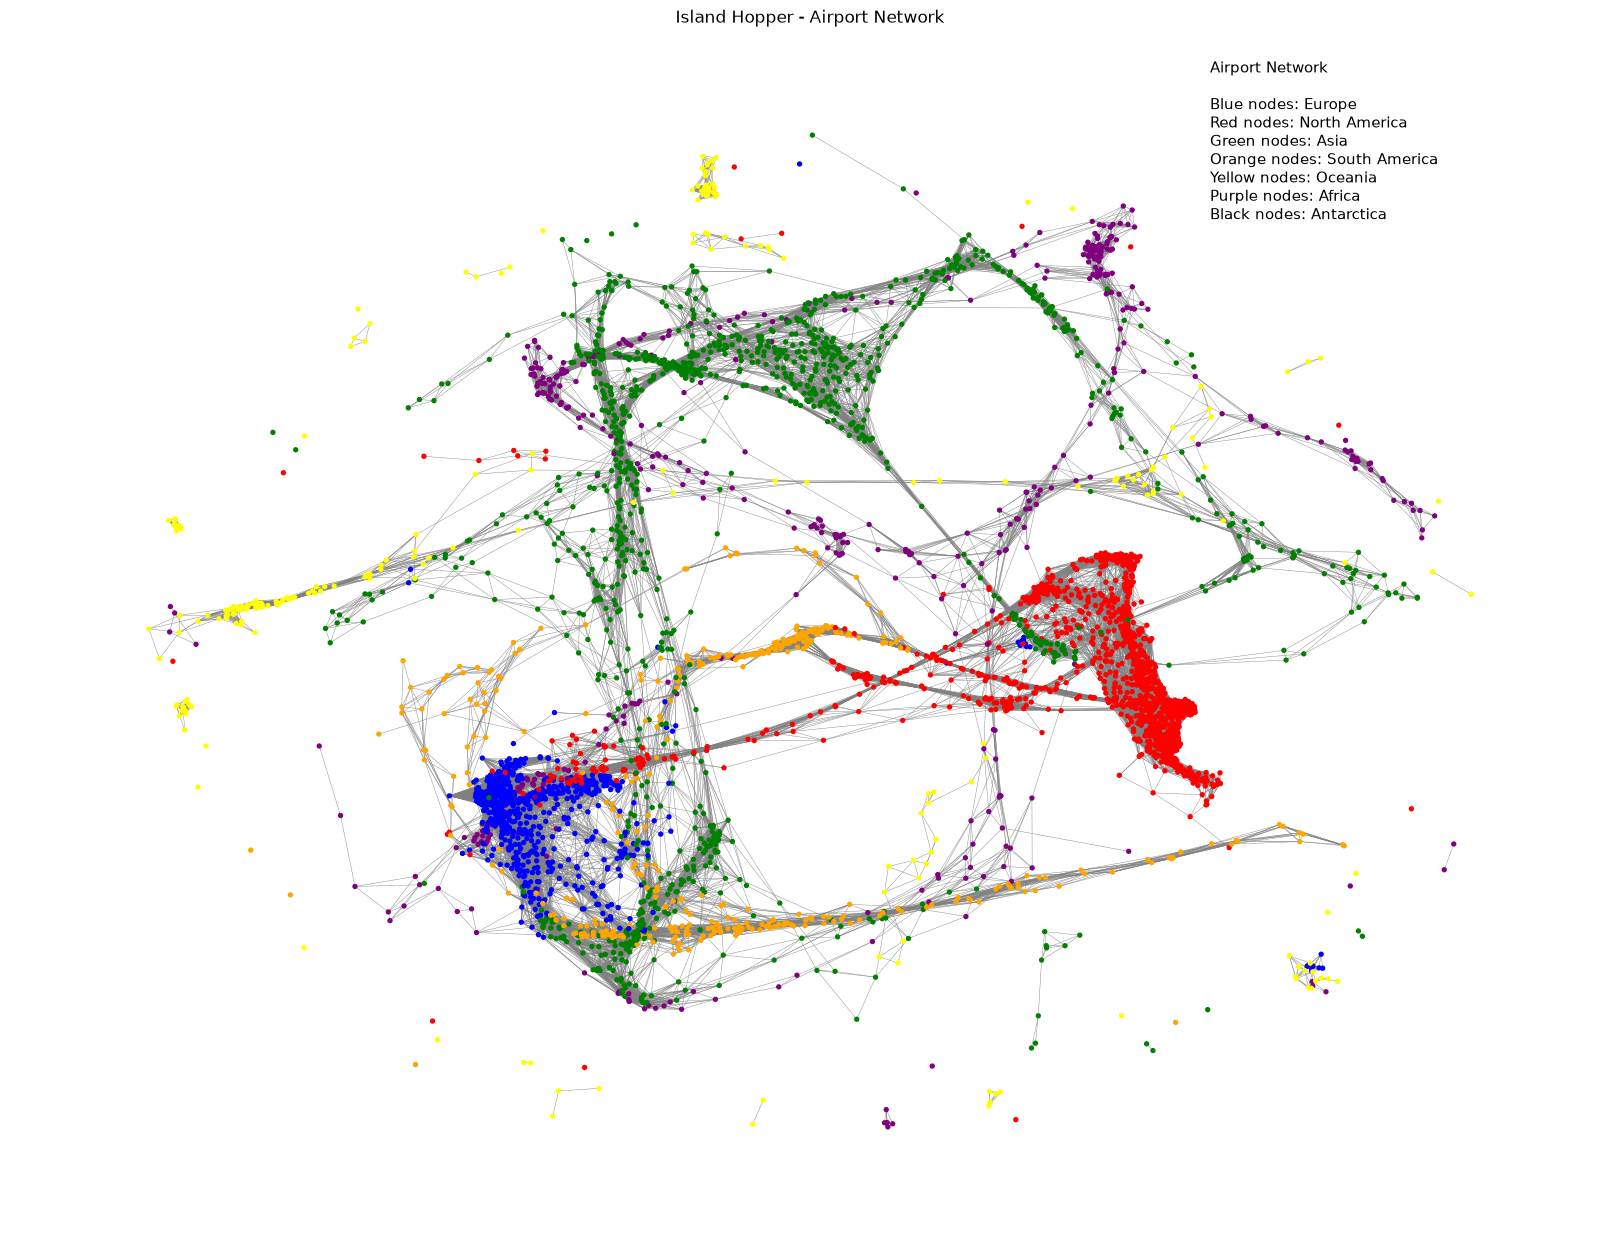

In [31]:
# Visualizing the 'airports' graph
VisualizeEntireGraph(airports)

## 6. BFS: What is the minimum amount of stops needed to reach an airport?

To find the minimum amount of stops needed to reach a node in a graph, it is possible to use the Breadth-First Search algorithm in the entire airport network. `breadthFirstSearch` travels the graph level by level, starting from the origin airport `id`. Each level represents an additional edge from the origin. Since the BFS explores nodes in increasing order of distance from the origin, the first time a node contains the `municipality` in the destination city, the algorithm guarantees a path with the minimum number of edges. The function `breadthFirstSearch` returns the resulting path and its estimated travelling time.

In this notebook, the origin airport is specified directly using the `id` of it. In the main version of the project, in `island_hopper`, the user can enter a starting city, then can choose whichever airport to start from using `input()`. The project then uses this input to identify the corresponding origin airport `id` automatically.

In [ ]:
# Flight that starts from Milan Malpensa Airport and searches for the first airport that is in Sydney.
# It is possible to replace "Sydney" with another city such as "London" or "Tokyo".
# However, some cities are unreachable, such as "New York" or "Rio De Janeiro".
# This is because the maximum range of the small airplane for the `airports` is too small for it to reach those cities.
# If the range gets increased, then the airports in those cities could potentially get reached.
result = breadthFirstSearch(airports, "4340", "sydney")

if result is not None:
    path, totalTime = result

    print(f"Number of flights: {len(path) - 2}")
    print(f"Total journey time: {totalTime:.2f} hours")
    print()

    for airportId in path:
        print(airports[airportId]["name"])
else:
    print("Something went wrong!")

Number of flights: 43
Total journey time: 92.42 hours

Milan Malpensa International Airport
Munich Airport
Copernicus Wrocław Airport
Lublin Airport
Zhytomyr Airport
Bryansk International Airport
Donskoye Airport
Ulyanovsk Baratayevka Airport
Izhevsk Airport
Koltsovo Airport
Tobolsk Remezov Airport
Omsk Central Airport
Pavlodar International Airport
Oskemen International Airport
Altay Xuedu Airport
Khovd Airport
Altai Airport
Bayankhongor Airport
Dalanzadgad Airport
Wuhai Airport
Yan'an Nanniwan Airport
Guangzhou MR Air Base / Guanghua Airport
Changsha Huanghua International Airport
Sanming Shaxian Airport
Kaohsiung International Airport
Laoag International Airport
Subic Bay International Airport / Naval Air Station Cubi Point
Evelio Javier Airport
Cotabato (Awang) Airport
Naha Airport
Sultan Babullah Airport
Domine Eduard Osok Airport
Utarom Airport
Bilorai Airport
Oksibil Airport
Balimo Airport
Horn Island Airport
Coen Airport
Cairns International Airport
Proserpine Whitsunday Coast 

In [33]:
# Showing the point from up.
# Searching for a route from Milan Malpensa to an airport in New York.
print("Route to New York with a maximum range of 500 km:")
try:
    result500 = breadthFirstSearch(graph500, "4340", "new york")

    if result500 is not None:
        path500, time500 = result500
        print(f"Number of flights: {len(path500) - 1}")

except ValueError:
    print("No route found with a maximum range of 500 km.")


print("\nRoute to New York with a maximum range of 750 km:")
try:
    result750 = breadthFirstSearch(graph750, "4340", "new york")

    if result750 is not None:
        path750, time750 = result750
        print(f"Number of flights: {len(path750) - 1}")
except ValueError:
    print("No route found with a maximum range of 750 km.")

Route to New York with a maximum range of 500 km:
Place is unreachable! Increase the plane's max fuel tank!
No route found with a maximum range of 500 km.

Route to New York with a maximum range of 750 km:
Number of flights: 10


### Visualization of the minimum amount of stops needed to reach an airport

Using the libraries **NetworkX** and **Matplotlib**, the BFS' result was visualized. The `VisualizeRoute()` function constructs an undirected graph using `nx.Graph()`. Each airport in the path provided by the BFS is added as a node and an edge is created between every pair of consecutive airports in the path using `graph.add_edge()`. Using the function `DecryptID()` each node gets a description of its airport. **NetworkX** draws the resulting graph using **Matplotlib**.

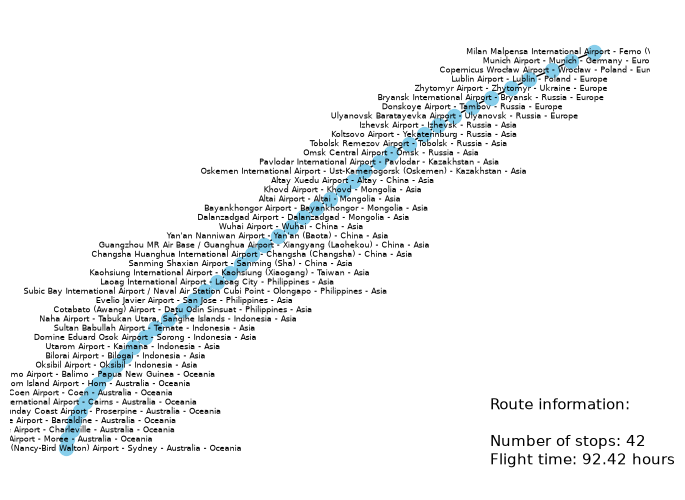

In [34]:
# Visualizing the minimum amount of stops needed and what are the actual locations.
VisualizeRoute(path,totalTime)

The route made by the BFS algorithm is visualized within the complete airport network using `VisualizeRouteInEntireGraph()`. The function constructs an undirected graph from `airports`, adding every airport as a node and every available connection as an edge.  **NetworkX** draws the resulting graph using **Matplotlib**.

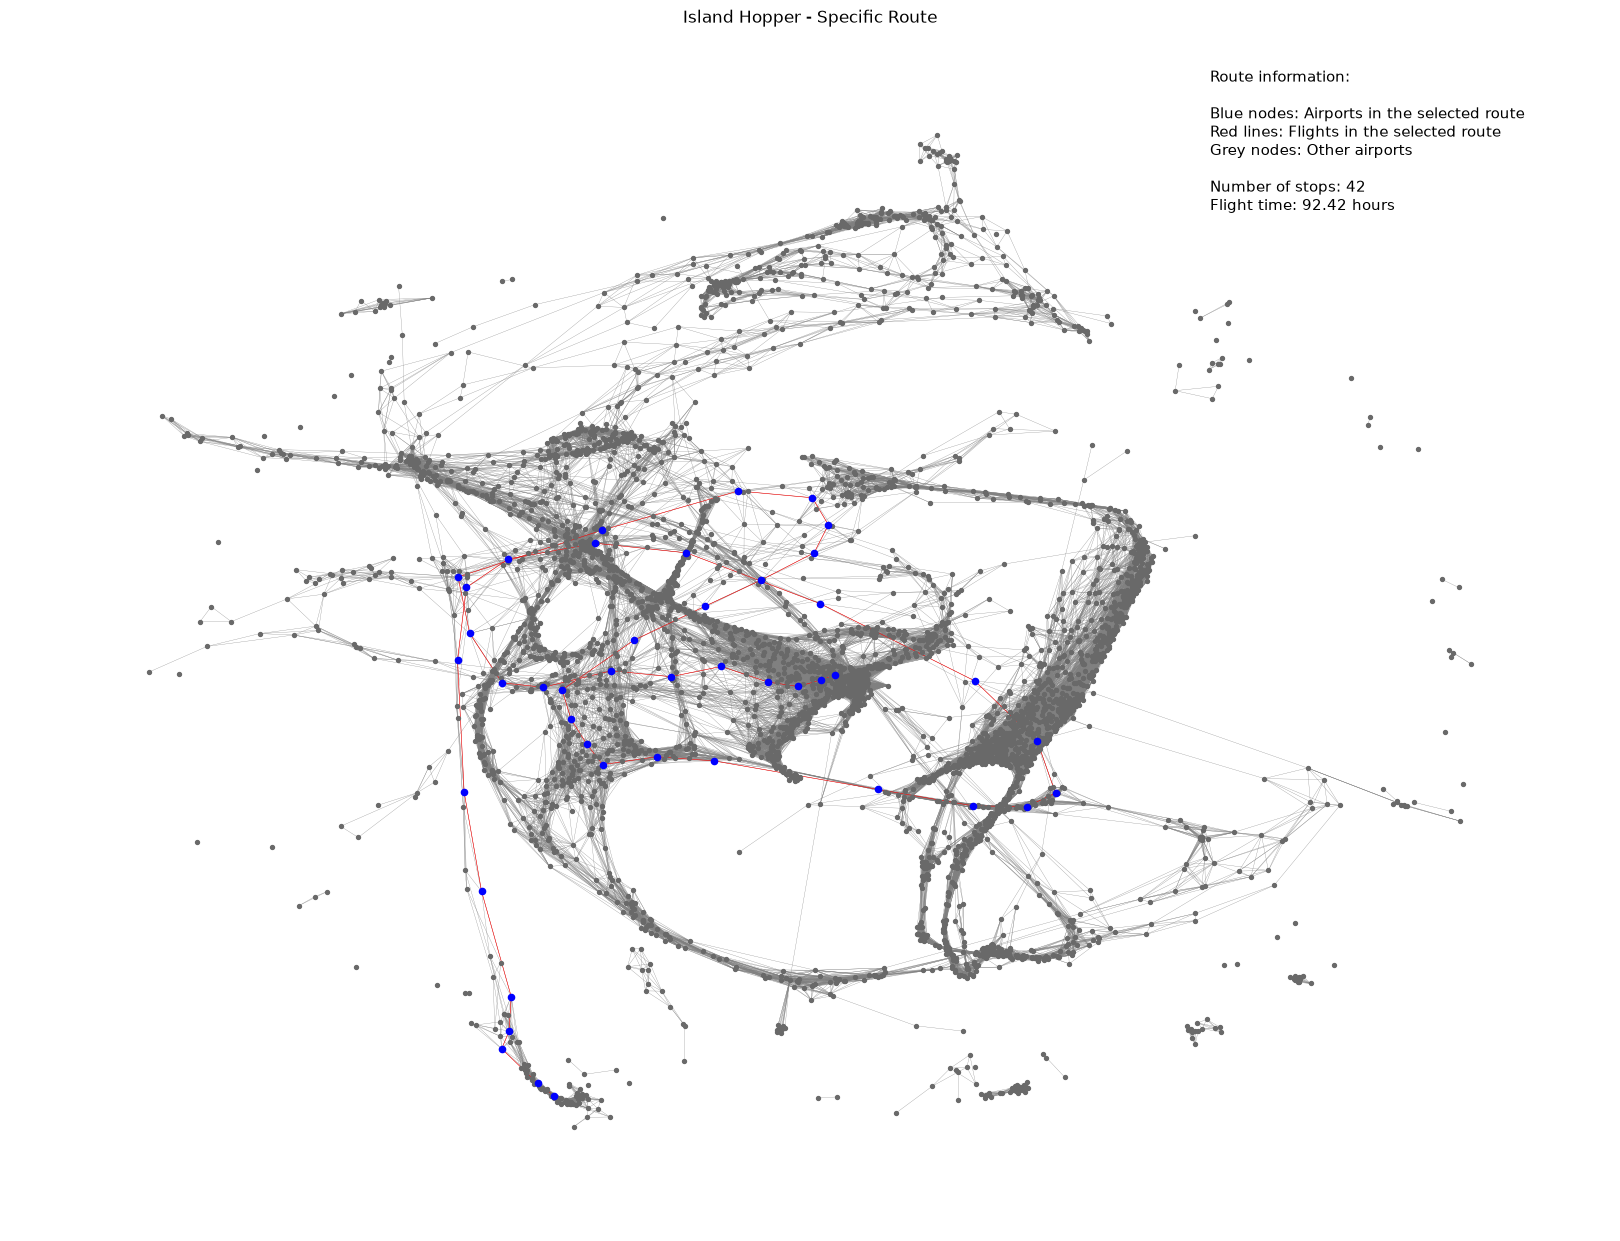

In [35]:
# Visualizing the previous path in a network of all airports.
VisualizeRouteInEntireGraph(path,airports,totalTime)

## 7. BFS: What is the farthest airport that you can reach with at most 10 stops?

To find the farthest airport that you can reach with at most 10 stops, the same Breadth-First Search algorithm was used in the entire airport graph, but was modified a bit. Instead of looking for the first time a node contains the `municipality` in the destination city, it explores all reachable airports up to the specified graph level. Then, it uses the `haversineFormula` to calculate the geographical distance between the origin an each reachable airport, returning the one with the biggest distance.

As in the previous functionality, some destinations may remain unreachable due the small airplane's maximum flight range. However, the higher the maximum range is, the higher the distance between the origin airport and the airport at the specified graph level will be.

In [36]:
# Finding the farthest airport reachable within 10 flights.
print("Farthest airport reachable within 10 flights with a maximum range of 500 km:")
try:
    # Finding the graph for a maximum range of 500 km
    result500 = FurthestPointFunction(graph500, "4340", 10)

    if result500 is not None:
        furthestPointInfoTuple500, furthestPointPath500, furthestPointTime500 = result500
        furthestAirportId500 = furthestPointInfoTuple500[0]
        furthestPointDistance500 = furthestPointInfoTuple500[2]

        print(f"Farthest reachable airport: {airports[furthestAirportId500]['name']}")
        print(f"Distance from Milan Malpensa: {round(furthestPointDistance500, 2)} km")
        print(f"Number of flights: {len(furthestPointPath500) - 2}")
        print(f"Total journey time: {round(furthestPointTime500, 2)} hours")

except ValueError:
    print("No reachable airport found with a maximum range of 500 km.")

print("\nFarthest airport reachable within 10 flights with a maximum range of 750 km:")
try:
    # Finding the graph for a maximum range of 750 km
    result750 = FurthestPointFunction(graph750, "4340", 10)

    if result750 is not None:
        furthestPointInfoTuple750, furthestPointPath750, furthestPointTime750 = result750
        furthestAirportId750 = furthestPointInfoTuple750[0]
        furthestPointDistance750 = furthestPointInfoTuple750[2]

        print(f"Farthest reachable airport: {airports[furthestAirportId750]['name']}")
        print(f"Distance from Milan Malpensa: {round(furthestPointDistance750, 2)} km")
        print(f"Number of flights: {len(furthestPointPath750) - 2}")
        print(f"Total journey time: {round(furthestPointTime750, 2)} hours")

except ValueError:
    print("No reachable airport found with a maximum range of 750 km.")

Farthest airport reachable within 10 flights with a maximum range of 500 km:
Farthest reachable airport: Zahedan International Airport
Distance from Milan Malpensa: 4840.01 km
Number of flights: 10
Total journey time: 25.06 hours

Farthest airport reachable within 10 flights with a maximum range of 750 km:
Farthest reachable airport: Ranai Airport
Distance from Milan Malpensa: 10443.26 km
Number of flights: 10
Total journey time: 41.39 hours


### Visualization of the farthest airport that you can reach with at most 10 stops

Using the libraries **NetworkX** and **Matplotlib**, the BFS' result of the farthest airport was visualized. The `VisualizeRoute()` function constructs an undirected graph using `nx.Graph()`. Each airport in the path provided by the BFS is added as a node and an edge is created between every pair of consecutive airports in the path using `graph.add_edge()`. Using the function `DecryptID()` each node gets a description of its airport. **NetworkX** draws the resulting graph using **Matplotlib**.

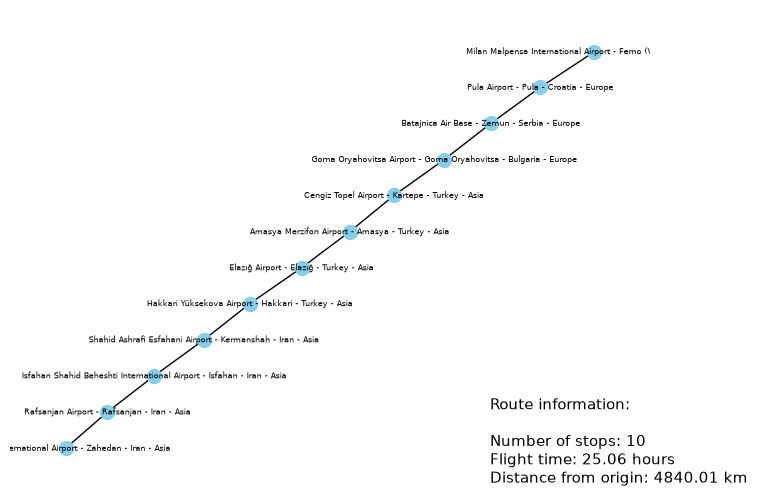

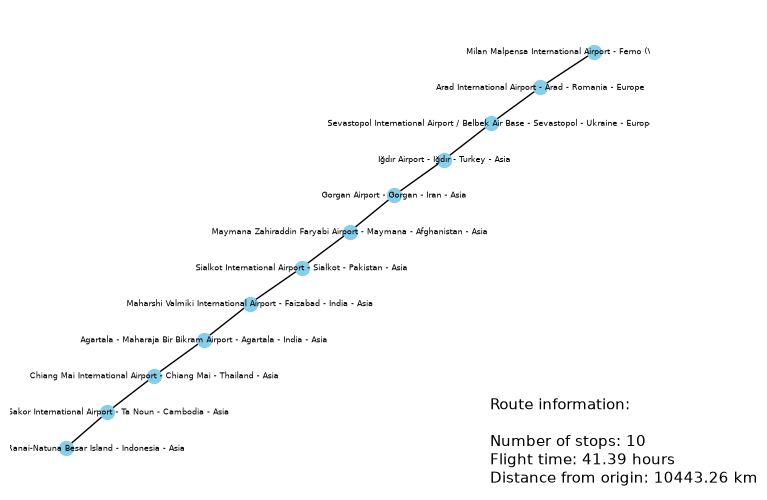

In [37]:
# Route visualization of the 500 km maximum range graph
VisualizeRoute(furthestPointPath500,furthestPointTime500,furthestPointDistance500)

# Route visualization of the 750 km maximum range graph
VisualizeRoute(furthestPointPath750,furthestPointTime750,furthestPointDistance750)

The BFS route was also drawn on the entire airport network using `VisualizeRouteInEntireGraph()`.

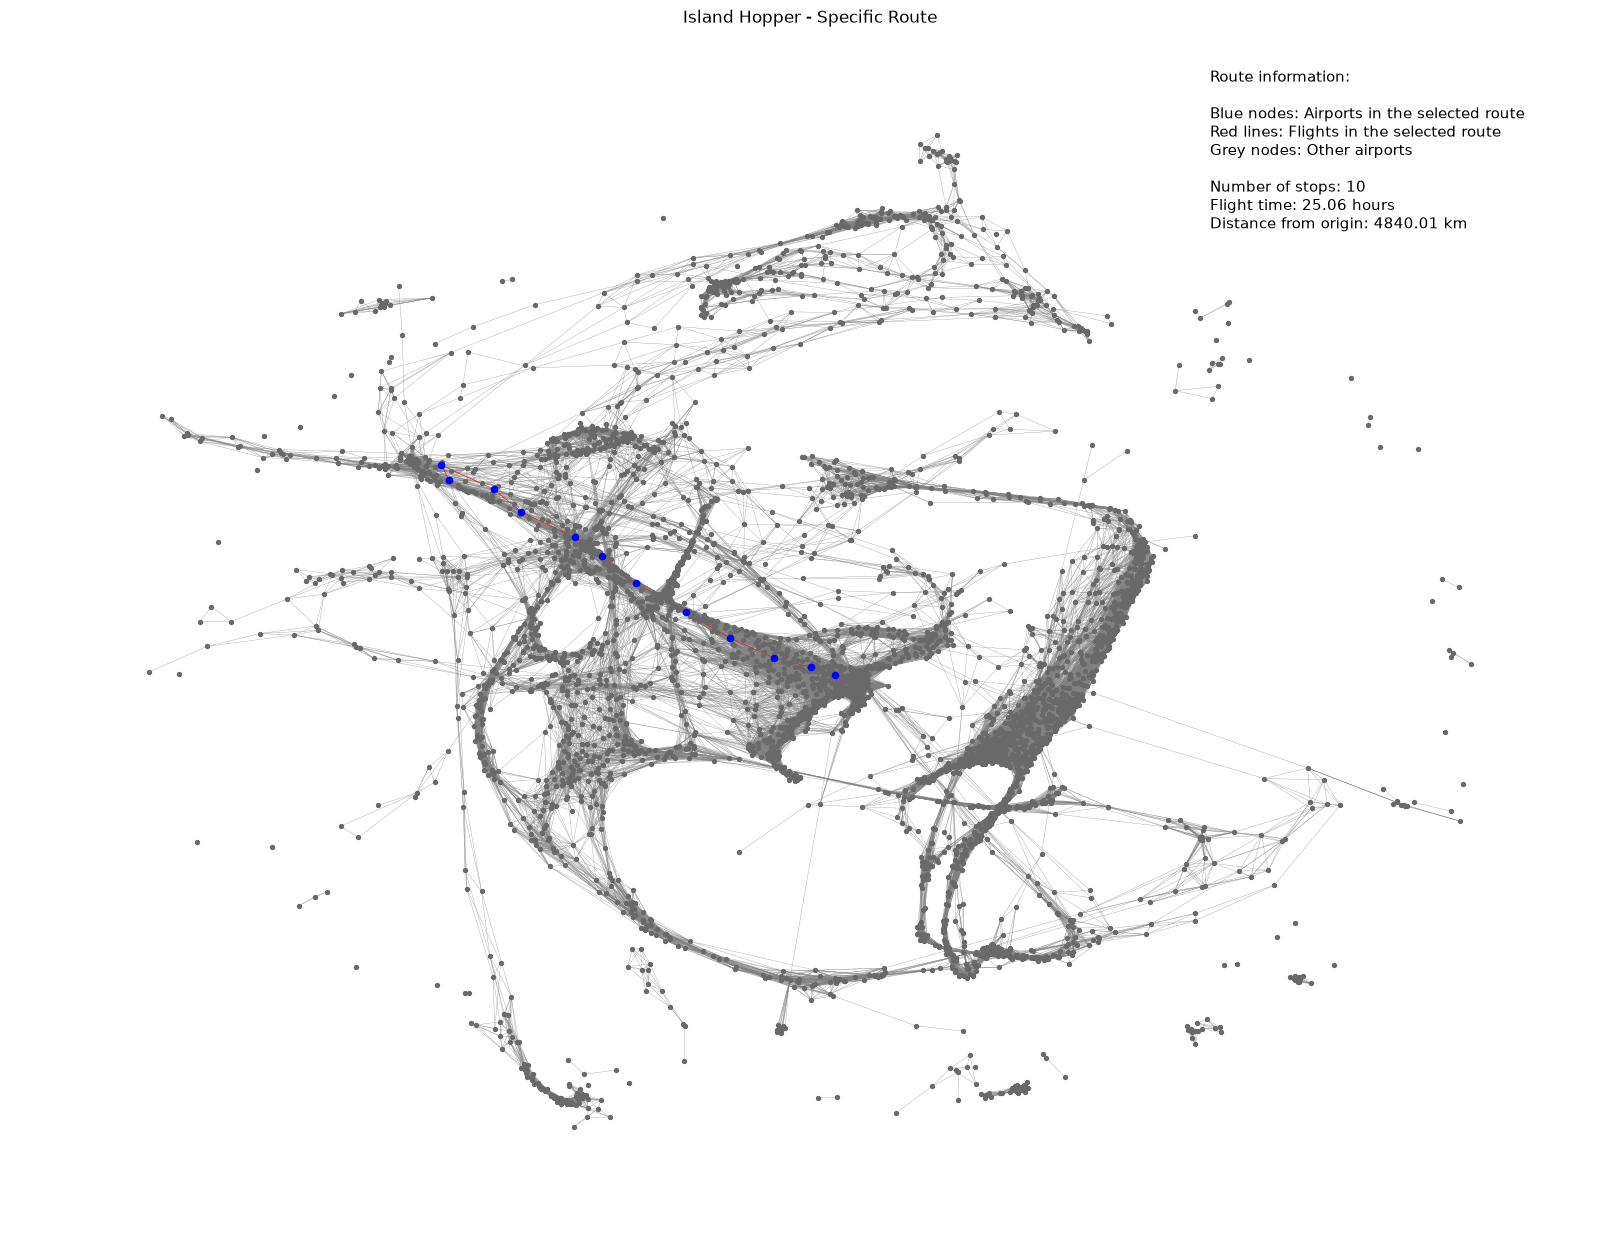

In [38]:
# Visualization over the entire network.
VisualizeRouteInEntireGraph(furthestPointPath500,airports,furthestPointTime500,furthestPointDistance500)

## 8. Dijkstra: What is the minimum amount of time needed to reach an airport?

To find the minimum amount of stops needed to reach a node in a graph, it is possible to use the Dijkstra algorithm in the entire airport network. The `distances` dictionary stores the minimum known travel time to each node. Every time an `unvisited` node with the lowest accumulated cost appears, it updates `distances`. `MinimumTimeFunction` returns the path with the shortest time.

The same maximum range constraint also applies to this route. The higher the maximum range, the lower the amount of time needed to get from one airport to another will be.


In [39]:
# Comparing the minimum-time routes with different maximum flight ranges.
print("Route to Sydney with a maximum range of 500 km:")
try:
    dijkstraResult500 = MinimumTimeFunction(graph500, "4340", "sydney")

    if dijkstraResult500 is not None:
        dijkstraPath500, dijkstraTime500 = dijkstraResult500

        print(f"Number of flights: {len(dijkstraPath500) - 2}")
        print(f"Minimum journey time: {round(dijkstraTime500, 2)} hours")

except ValueError:
    print("No route found with a maximum range of 500 km.")


print("\nRoute to Sydney with a maximum range of 750 km:")
try:
    dijkstraResult750 = MinimumTimeFunction(graph750, "4340", "sydney")

    if dijkstraResult750 is not None:
        dijkstraPath750, dijkstraTime750 = dijkstraResult750

        print(f"Number of flights: {len(dijkstraPath750) - 2}")
        print(f"Minimum journey time: {round(dijkstraTime750, 2)} hours")

except ValueError:
    print("No route found with a maximum range of 750 km.")

Route to Sydney with a maximum range of 500 km:
Number of flights: 42
Minimum journey time: 86.9 hours

Route to Sydney with a maximum range of 750 km:
Number of flights: 8
Minimum journey time: 26.23 hours


### Visualization of the minimum amount of time needed to reach an airport

Using the libraries **NetworkX** and **Matplotlib**, the Dijkstra's result of the minimum amount of time needed to reach an airport was visualized. The `VisualizeRoute()` function constructs an undirected graph using `nx.Graph()`. Each airport in the path provided by the BFS is added as a node and an edge is created between every pair of consecutive airports in the path using `graph.add_edge()`. Using the function `DecryptID()` each node gets a description of its airport. **NetworkX** draws the resulting graph using **Matplotlib**.

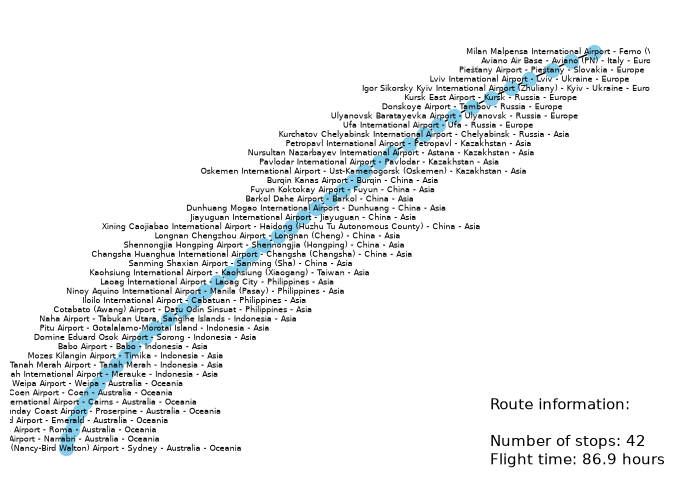

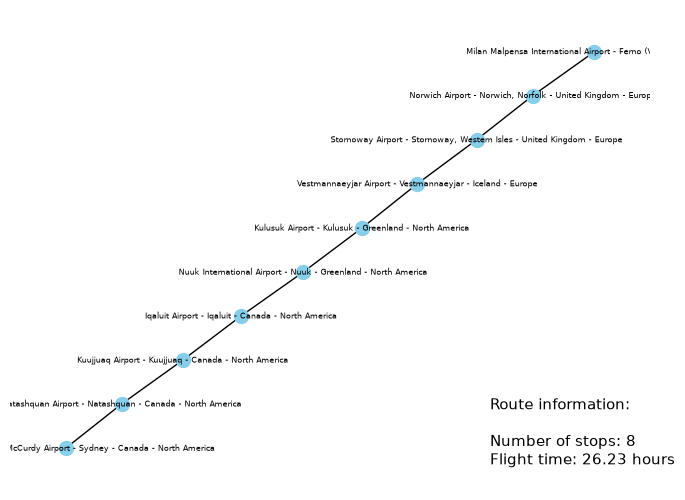

In [40]:
# Visualizing the Dijkstra path for 500 km and 750 km
VisualizeRoute(dijkstraPath500,dijkstraTime500)
VisualizeRoute(dijkstraPath750,dijkstraTime750)

The Dijkstra route was also drawn on the entire airport network using `VisualizeRouteInEntireGraph()`.

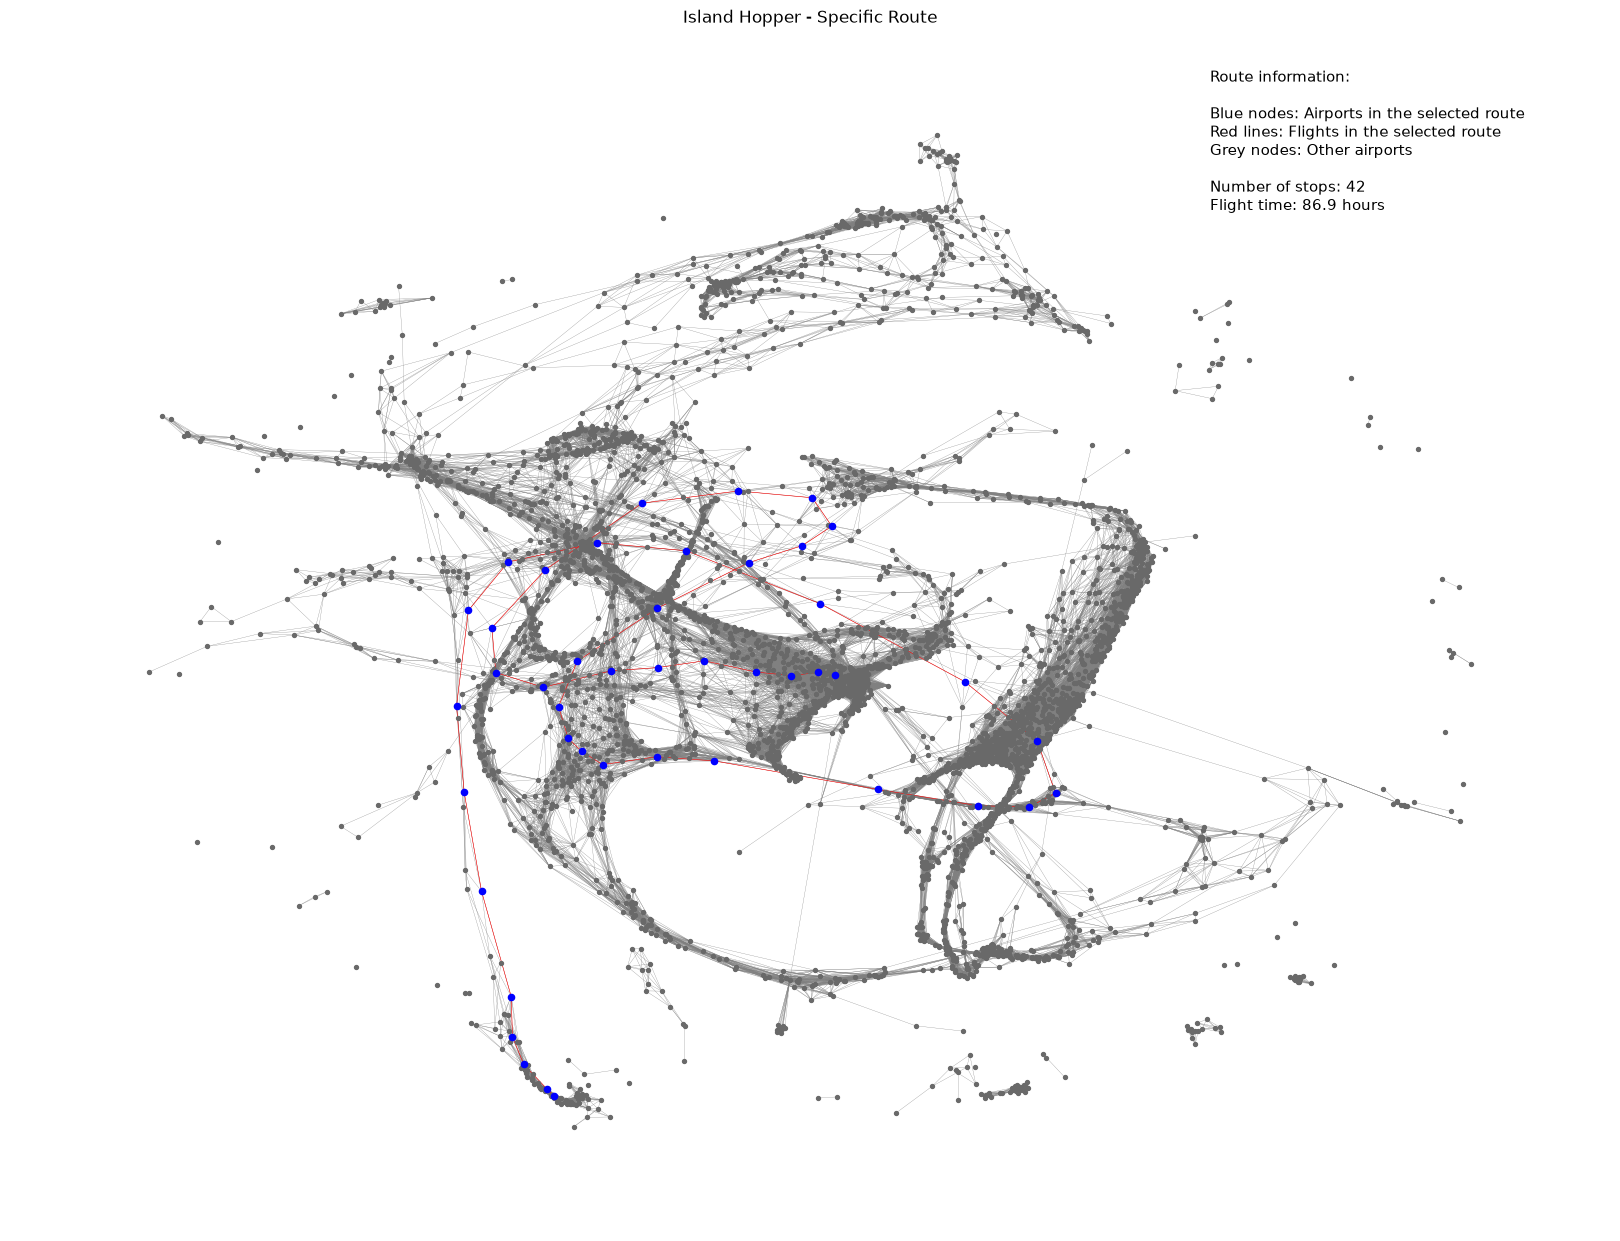

In [ ]:
# The visualization of the Dijkstra network graph
VisualizeRouteInEntireGraph(dijkstraPath500,airports,dijkstraTime500)